In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import torch
import xarray as xa
import cartopy.crs as ccrs

import sys,os
testdir = os.path.dirname(os.getcwd() + '/')
srcdir = '..'
sys.path.insert(0, os.path.abspath(os.path.join(testdir, srcdir)))
from ocean_wave_tracing import Wave_tracing

from ocean_wave_tracing.util_metric import SphericalMetric, CartesianMetric
from ocean_wave_tracing.util_derivatives import Autoderivative_ESPG

plt.rcParams.update({
    'font.size': 16,
    'axes.labelsize': 18,
    'axes.titlesize': 20,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'mathtext.fontset': 'cm',
    'font.family': 'serif',
    'text.usetex': True
})


import warnings

warnings.filterwarnings("ignore", category=RuntimeWarning)

In [2]:
dataset = xa.open_dataset("nk_subset_NK_new.nc")
dataset

<xarray.Dataset> Size: 43MB
Dimensions:           (time: 12, Y: 400, X: 500)
Coordinates:
  * time              (time) datetime64[ns] 96B 2026-04-02T12:00:00 ... 2026-...
  * Y                 (Y) int32 2kB 400000 400800 401600 ... 718400 719200
  * X                 (X) int32 2kB 1200000 1200800 1201600 ... 1598400 1599200
    lon               (Y, X) float64 2MB ...
    lat               (Y, X) float64 2MB ...
    depth             float64 8B ...
Data variables:
    u_eastward        (time, Y, X) float32 10MB ...
    v_northward       (time, Y, X) float32 10MB ...
    h                 (Y, X) float64 2MB ...
    projection_stere  int32 4B ...
    Uwind_eastward    (time, Y, X) float32 10MB ...
    Vwind_northward   (time, Y, X) float32 10MB ...
Attributes: (12/40)
    id:                         aedbc706-e84b-4a24-a483-4f944f9f704a
    naming_authority:           no.met
    operational_status:         Operational
    iso_topic_category:         oceans
    activity_type:              Numerical Simulation
    keywords_vocabulary:        GCMDSK:GCMD Science Keywords:https://gcmd.ear...
    ...                         ...
    summary:                    Norkyst_v3-800m (Norwegian Coast 800m horizon...
    title_no:                   120 timers prognoser fra havmodellen Norkyst_...
    summary_no:                 NorKyst_v3-800m (Norske kystområder med 800m ...
    contributor_name:           Magne Simonsen, Mateusz Matuszak
    contributor_role:           Technical contact, Metadata author
    contributor_email:          magnes@met.no, mateuszm@met.no

In [3]:
lofoten_h = dataset.h.values

analysis_date = '2026-04-02T01'
lofoten_u=dataset.u_eastward.sel(time=analysis_date, method="nearest")
lofoten_v=dataset.v_northward.sel(time=analysis_date, method="nearest")

lofoten_lon=dataset.lon.data
lofoten_lat=dataset.lat.data

X = dataset.X.data
Y = dataset.Y.data
nx = len(X)
ny = len(Y)
dx=dy=X[1]-X[0]
nb_wave_rays = 200#550#nx
T = 50000
nt = 300 # 1500
wave_period = 10 #s
X0, XN = X[0], X[-1] 
Y0, YN = Y[0], Y[-1]

LON = dataset.lon.data
LAT = dataset.lat.data
nlon = len(LON)
nlat = len(LAT)
dlon=LON[1]-LON[0]
dlat=LAT[1]-LAT[0]
nb_wave_rays = 200#550#nx
T = 50000
nt = 300 # 1500
wave_period = 10 #s
LON0, LONN = LON[0], LON[-1] 
LAT0, LATN = LAT[0], LAT[-1]


i_w_side = 'left'
theta0=0


In [4]:
# cartesian
wt_cart = Wave_tracing(U=lofoten_u.rename({'X':'x','Y':'y'})*1, V=lofoten_v.rename({'X':'x','Y':'y'})*1, nx=nx, ny=ny, nt=nt, T=T, d=lofoten_h, dx=dx, dy=dy, nb_wave_rays=nb_wave_rays, 
                       domain_X0=X0, domain_XN=XN, domain_Y0=Y0, domain_YN=YN, metric=CartesianMetric())
wt_cart.set_initial_condition(wave_period, theta0 ,incoming_wave_side=i_w_side)
wt_cart.solve()

# spherical
wt_spherical = Wave_tracing(U=lofoten_u.rename({'X':'x','Y':'y'})*1, V=lofoten_v.rename({'X':'x','Y':'y'})*1, nx=nx, ny=ny, nt=nt, T=T, d=lofoten_h, dx=dx, dy=dy, nb_wave_rays=nb_wave_rays, 
                       domain_X0=X0, domain_XN=XN, domain_Y0=Y0, domain_YN=YN, metric=SphericalMetric(), derivative_scheme=Autoderivative_ESPG, ESPG_needed=True)
wt_spherical.set_initial_condition(wave_period, theta0+np.pi/3, incoming_wave_side=i_w_side)
wt_spherical.solve()


tensor([[        nan,         nan,         nan,         nan],
        [        nan,         nan,         nan,         nan],
        [        nan,         nan,         nan,         nan],
        [        nan,         nan,         nan,         nan],
        [        nan,         nan,         nan,         nan],
        [        nan,         nan,         nan,         nan],
        [        nan,         nan,         nan,         nan],
        [        nan,         nan,         nan,         nan],
        [        nan,         nan,         nan,         nan],
        [        nan,         nan,         nan,         nan],
        [        nan,         nan,         nan,         nan],
        [        nan,         nan,         nan,         nan],
        [        nan,         nan,         nan,         nan],
        [        nan,         nan,         nan,         nan],
        [        nan,         nan,         nan,         nan],
        [        nan,         nan,         nan,         nan],
        

c:\Users\NSche\OneDrive\Desktop\UiB\Master\ocean_wave_tracing_torch_fork\ocean_wave_tracing\ocean_wave_tracing\ocean_wave_tracing.py:300: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\Users\task_177771675088222\croot\libtorch_1777716875698\work\torch\csrc\utils\tensor_new.cpp:256.)
  xs, ys =  torch.tensor(self.derivative_scheme.backtransformer.transform(xs, ys), dtype=torch.float32)


ValueError: Pass the 2D latitude field and projected grid bounds to SphericalMetric(lat, x0, xN, y0, yN).

In [ ]:
proj4 = ("+proj=stere +lat_0=90 +lat_ts=60 +lon_0=70 +x_0=3369600 +y_0=1844800 +a=6378137 +b=6356752.3142 +units=m +no_defs +type=crs") #NK800 #
lons_wc,lats_wc=wt_cart.to_latlon(proj4)

C:\Users\NSche\AppData\Local\Temp\ipykernel_31740\931116437.py:30: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


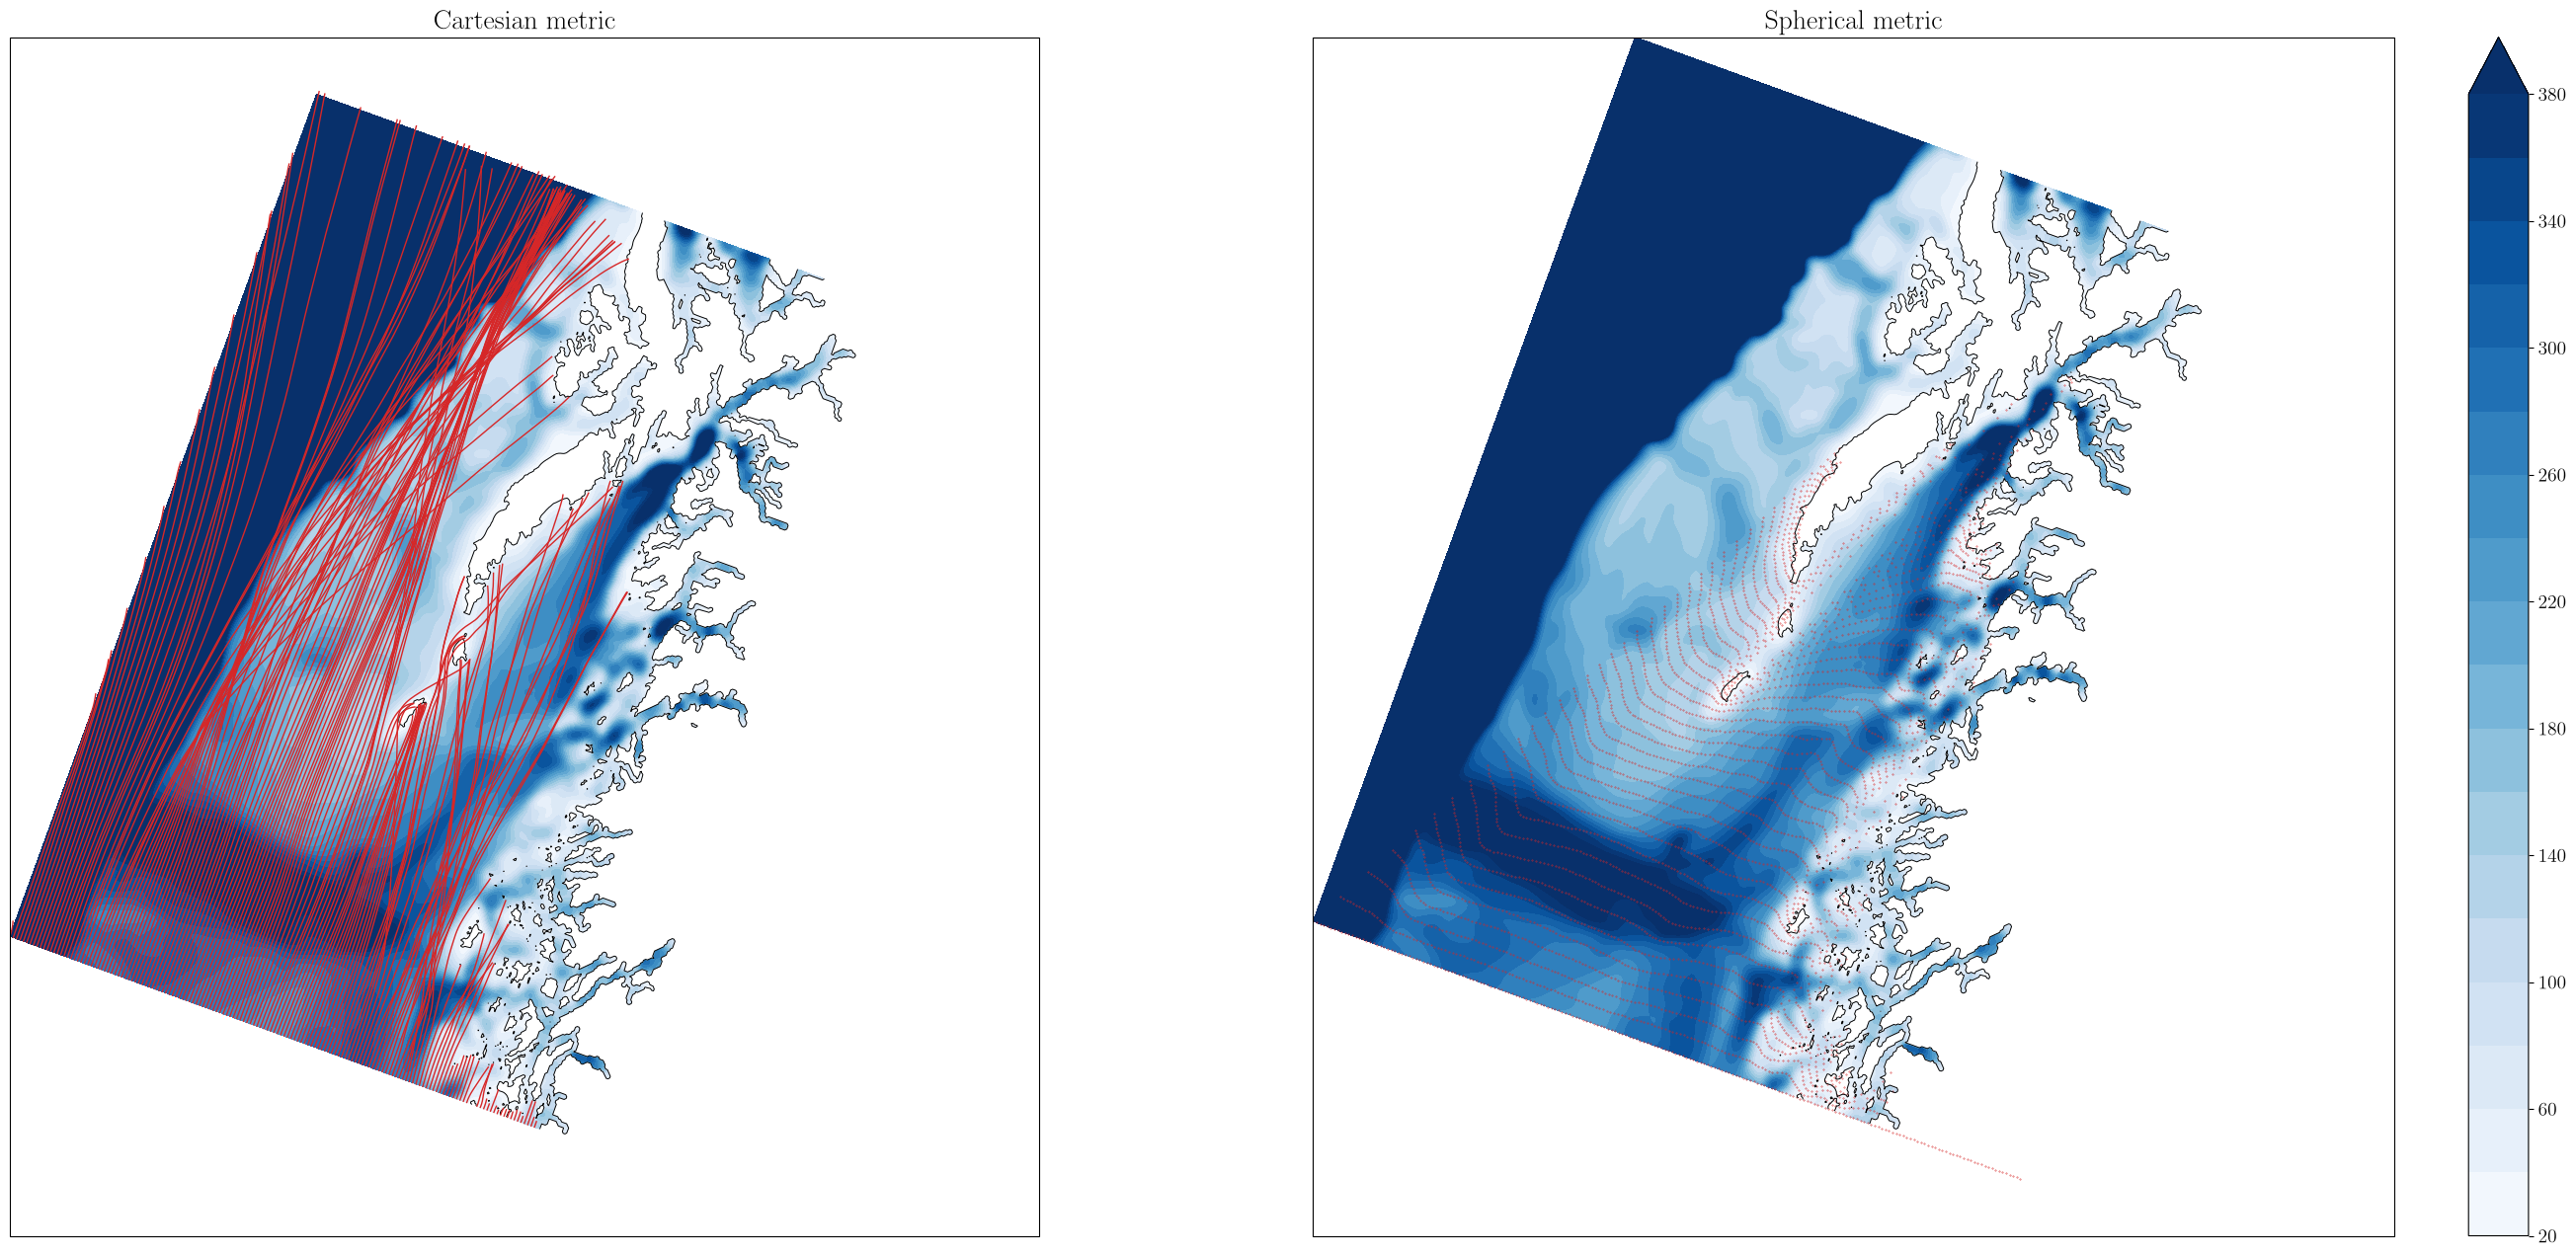

In [ ]:

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(30,13), subplot_kw={'projection': ccrs.NorthPolarStereo()})
ax1.contourf(lofoten_lon, lofoten_lat, lofoten_h, cmap="Blues", levels=np.arange(20,400,20), extend="max", transform=ccrs.PlateCarree())
depth_plot =ax2.contourf(lofoten_lon, lofoten_lat, lofoten_h, cmap="Blues", levels=np.arange(20,400,20), extend="max", transform=ccrs.PlateCarree())

#ax.contourf(lofoten_lon, lofoten_lat, lofoten_h, levels=[np.nanmin(lofoten_h), 20], colors=['lightgray'], zorder=3)
ax1.contour(lofoten_lon, lofoten_lat, lofoten_h, colors="black", linewidth=.7, levels=[20], extend="max", transform=ccrs.PlateCarree())
ax2.contour(lofoten_lon, lofoten_lat, lofoten_h, colors="black", linewidth=.7, levels=[20], extend="max", transform=ccrs.PlateCarree())

step=1
for i in range(0,wt_cart.nb_wave_rays,step):
    if i == 0:
        ax1.plot(lons_wc[i,:],lats_wc[i,:],'-',c='tab:red',
                transform=ccrs.PlateCarree(),alpha=1,lw=1,label='Wave ray')
    else:
        ax1.plot(lons_wc[i,:],lats_wc[i,:],'-',c='tab:red',transform=ccrs.PlateCarree(),alpha=1,lw=1)

step=1
for i in range(0,wt_spherical.nb_wave_rays,step):
    if i == 0:
        ax2.scatter(wt_spherical.ray_x[i,:],wt_spherical.ray_y[i,:],s=0.1,c='tab:red',
                transform=ccrs.PlateCarree(),alpha=1,lw=1,label='Wave ray')
    else:
        ax2.scatter(wt_spherical.ray_x[i,:],wt_spherical.ray_y[i,:],s=0.1,c='tab:red',transform=ccrs.PlateCarree(),alpha=1,lw=1)

ax2.grid()

ax1.set_title("Cartesian metric")
ax2.set_title("Spherical metric")

fig.show()

fig.colorbar(depth_plot)
fig.tight_layout()

In [ ]:
#torch.set_printoptions(threshold=float('inf'))
#np.set_printoptions(threshold=np.inf)

print(wt_spherical.ray_x.T)
#print(lons_wc.T)

tensor([[13.6608, 13.6314, 13.6021,  ...,  7.4872,  7.4539,  7.4205],
        [    nan,     nan,     nan,  ...,  7.7805,  7.7512,  7.7216],
        [    nan,     nan,     nan,  ...,  8.0830,  8.0576,  8.0313],
        ...,
        [    nan,     nan,     nan,  ...,     nan,     nan,     nan],
        [    nan,     nan,     nan,  ...,     nan,     nan,     nan],
        [    nan,     nan,     nan,  ...,     nan,     nan,     nan]])
